# Activity 5
John Rendell B. Tapire
CPE4A

The reference crops the number line, converts to grayscale, applies Otsu thresholding,
pads the image, and runs Tesseract. This version adds contour filtering to select tall
number-line characters while excluding the border, mounting holes, lower-right QR
code, and small bottom captions. No object detection model is used.

In [4]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Support a kernel started in either this activity folder or the project root.
activity_dir = Path.cwd()
if not (activity_dir / 'images').is_dir():
    activity_dir = activity_dir / 'Activity_05'
image_dir = activity_dir / 'images'
if not image_dir.is_dir():
    raise FileNotFoundError('Open the project root or this activity folder in VS Code.')

def show_stages(stages, columns=3):
    rows = (len(stages) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.6 * rows), squeeze=False)
    for axis, (title, picture) in zip(axes.flat, stages):
        axis.imshow(picture, cmap='gray' if picture.ndim == 2 else None)
        axis.set_title(title)
    for axis in axes.flat:
        axis.axis('off')
    plt.tight_layout()
    plt.show()


import os
import shutil
import pytesseract

# Tesseract is a separate application; pytesseract is its Python wrapper.
# An optional environment variable supports a custom installation without editing code.
tesseract_command = os.environ.get('TESSERACT_CMD') or shutil.which('tesseract')
if not tesseract_command:
    windows_install = Path(os.environ.get('ProgramFiles', 'C:/Program Files')) / 'Tesseract-OCR' / 'tesseract.exe'
    if windows_install.is_file():
        tesseract_command = str(windows_install)
if not tesseract_command:
    raise RuntimeError('Install Tesseract OCR with English data, then add it to PATH or set TESSERACT_CMD. See README.md.')
pytesseract.pytesseract.tesseract_cmd = tesseract_command
print('Tesseract version:', pytesseract.get_tesseract_version())

Tesseract version: 5.4.0.20240606


In [5]:
def prepare_plate(image):
    height, width = image.shape[:2]
    # Keep the central number band for every supplied style, including the single digit.
    crop = image[int(height * 0.12):int(height * 0.90),
                 int(width * 0.025):int(width * 0.975)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if cv2.countNonZero(binary) < binary.size / 2:
        binary = cv2.bitwise_not(binary)

    # Tall, narrow external contours represent characters. QR blocks and captions are
    # much shorter; plate-border contours are too wide. Holes inside letters are retained.
    contours, _ = cv2.findContours(255 - binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    character_boxes = []
    for contour in contours:
        x, y, box_width, box_height = cv2.boundingRect(contour)
        if (box_height >= height * 0.26 and box_height <= height * 0.78
                and width * 0.012 <= box_width <= width * 0.18
                and box_width / box_height < 1.0):
            character_boxes.append((x, y, box_width, box_height))
    character_boxes.sort(key=lambda box: box[0])
    if not character_boxes:
        return crop, binary, None, character_boxes

    # Copy only the selected characters onto white paper, excluding all other marks.
    isolated = np.full_like(binary, 255)
    for x, y, box_width, box_height in character_boxes:
        isolated[y:y + box_height, x:x + box_width] = binary[y:y + box_height, x:x + box_width]
    left = min(box[0] for box in character_boxes)
    top = min(box[1] for box in character_boxes)
    right = max(box[0] + box[2] for box in character_boxes)
    bottom = max(box[1] + box[3] for box in character_boxes)
    line = isolated[top:bottom, left:right]
    # Normalize character height while preserving aspect ratio, then add OCR padding.
    scale = 140 / line.shape[0]
    line = cv2.resize(line, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
    prepared = cv2.copyMakeBorder(line, 25, 25, 25, 25, cv2.BORDER_CONSTANT, value=255)
    return crop, binary, prepared, character_boxes

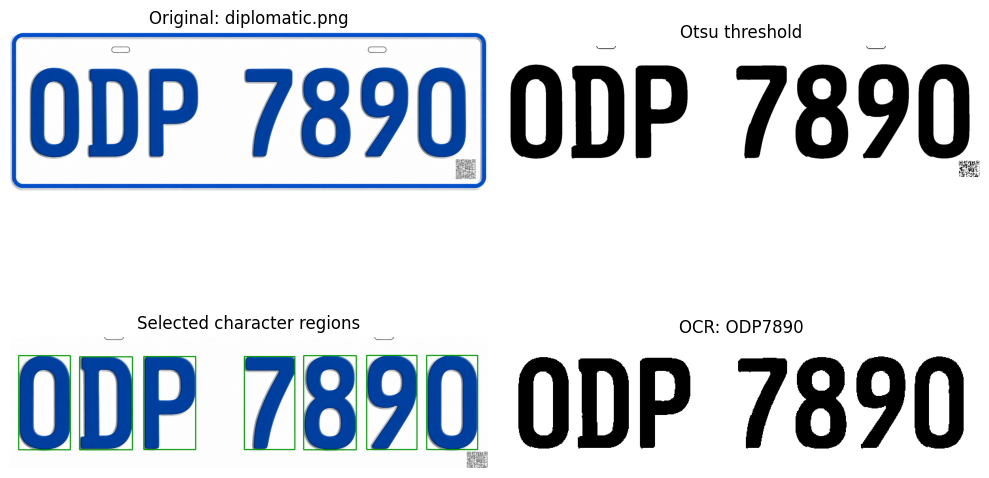

diplomatic.png: ODP7890 — OCR returned text; verify visually


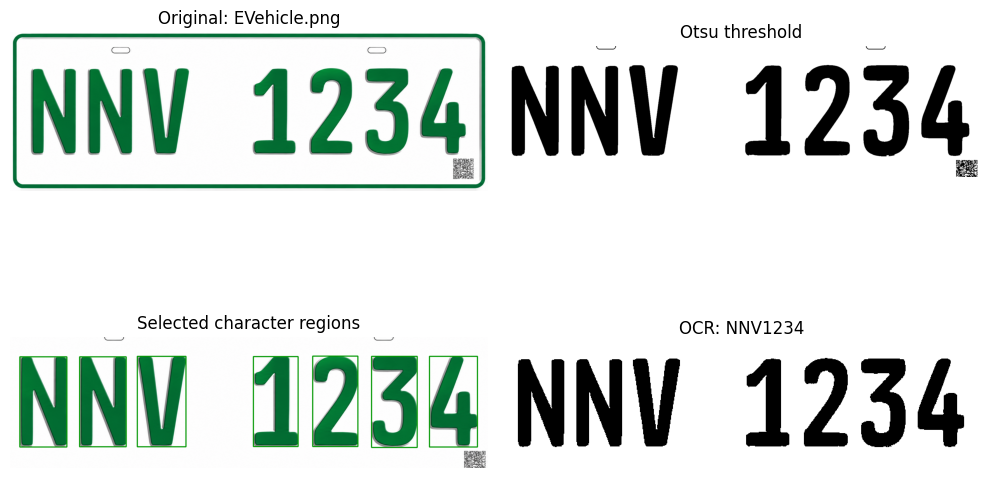

EVehicle.png: NNV1234 — OCR returned text; verify visually


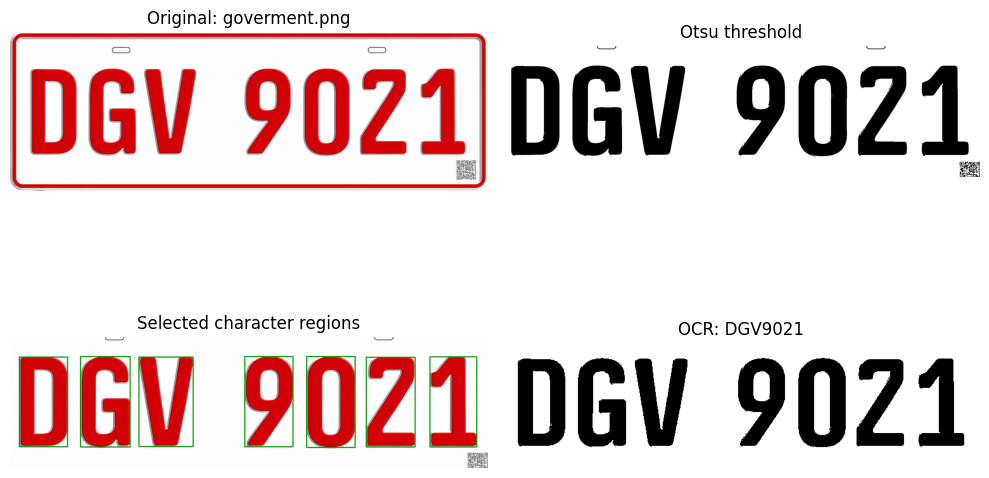

goverment.png: DGV9021 — OCR returned text; verify visually


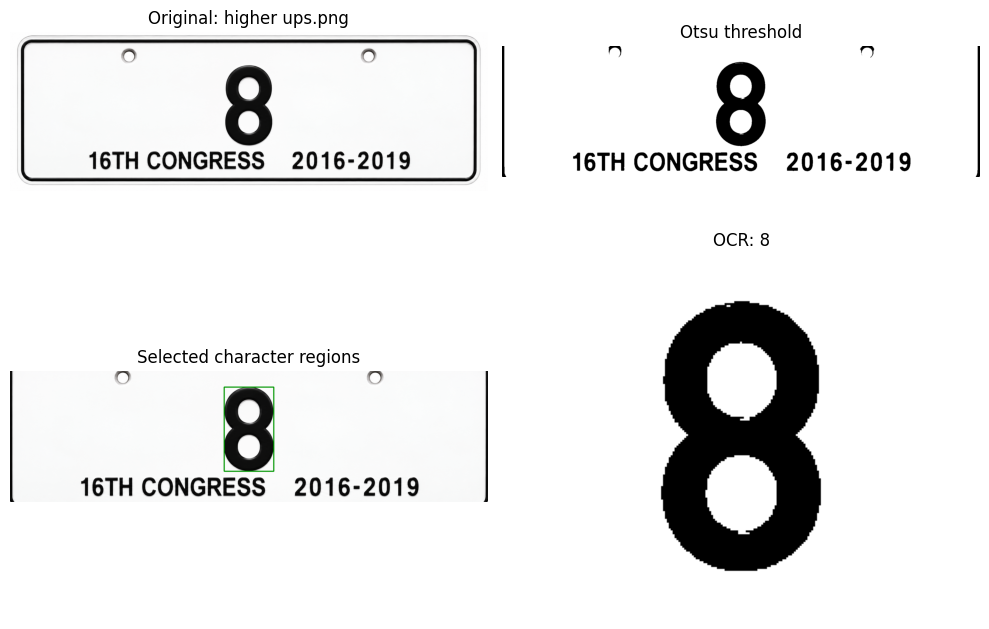

higher ups.png: 8 — OCR returned text; verify visually


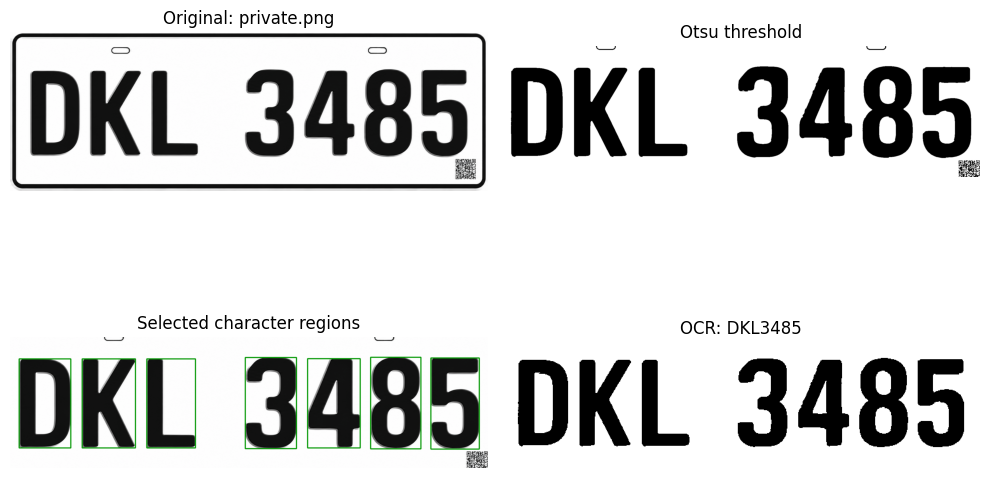

private.png: DKL3485 — OCR returned text; verify visually


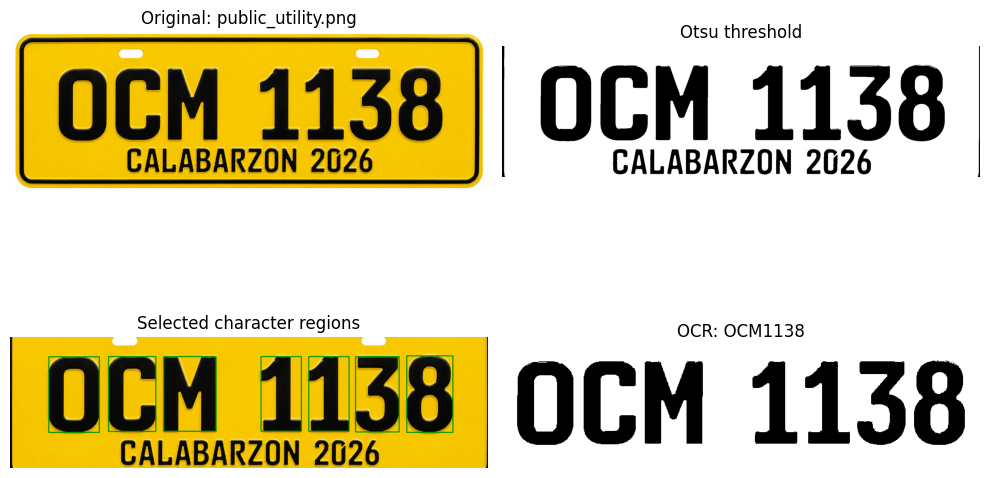

public_utility.png: OCM1138 — OCR returned text; verify visually


In [6]:
def recognize_plate(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(image_path)
    crop, binary, prepared, boxes = prepare_plate(image)
    if prepared is None:
        show_stages([('Original: ' + image_path.name, cv2.cvtColor(image, cv2.COLOR_BGR2RGB)),
                     ('Threshold', binary)], columns=2)
        return {'file': image_path.name, 'text': '', 'status': 'No character regions found'}

    # Single-character mode supports the special plate; others use single-line mode.
    page_mode = 10 if len(boxes) == 1 else 7
    config = f'--psm {page_mode} -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'
    raw_text = pytesseract.image_to_string(prepared, lang='eng', config=config).strip()
    text = ''.join(character for character in raw_text.upper() if character.isascii() and character.isalnum())
    annotated_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    for x, y, box_width, box_height in boxes:
        cv2.rectangle(annotated_crop, (x, y), (x + box_width, y + box_height), (0, 150, 0), 3)
    show_stages([('Original: ' + image_path.name, cv2.cvtColor(image, cv2.COLOR_BGR2RGB)),
                 ('Otsu threshold', binary), ('Selected character regions', annotated_crop),
                 ('OCR: ' + (text or '[no text returned]'), prepared)], columns=2)
    return {'file': image_path.name, 'text': text,
            'status': 'OCR returned text; verify visually' if text else 'OCR returned no text'}

plate_results = []
for image_path in sorted(image_dir.glob('*.png')):
    record = recognize_plate(image_path)
    plate_results.append(record)
    print(f'{record["file"]}: {record["text"] or "[unrecognized]"} — {record["status"]}')

OCR text is generated from pixels and may confuse similar letters and digits.
Compare the returned text with the original image and selected regions. No expected
plate strings or filename-to-result lookup is included in the recognition code.
The crop and contour thresholds assume a frontal plate filling most of the image;
full vehicle scenes would require a separate localization step.